<div style="background-color: RGB(255,114,0); padding: 24px;">
<h1 style="margin: 0; color: #fff;">BOTTLENECK — ANALYSE DU STOCK ET DES VENTES<br>Version améliorée (P13)</h1>
</div>

**Auteure** : Sabah Rizki — Data Analyst · **Base** : notebook du P6 (avril 2026) · **Version** : P13, octobre 2026

## Ce que fait ce notebook

Il reprend l'analyse du P6 (stock, ventes, marges du caviste BottleNeck) et la rend **fiable, rejouable et utile à la décision**. Toutes les améliorations viennent de la veille et d'un test comparatif de deux IA (Claude et Gemini, 6 essais notés sur 100) documenté dans le PDF joint.

| Lot | Amélioration | Pourquoi | Origine |
| --- | --- | --- | --- |
| Qualité des données | Contrôles automatiques Pandera : 64 règles, niveau BLOQUANT / ALERTE, rapport Excel | Le P6 contrôlait à la main et ses chiffres étaient saisis en dur | Essai IA retenu (C-P2, 91,9/100) + 3 ajouts |
| Qualité des données | Récapitulatif des erreurs **calculé**, comparé à celui du P6 | Le P6 annonçait 4 ventes à perte, son propre code en trouvait 7 | Audit du P6 |
| Jointure | Contrôle des clés par la table de liaison, avec assertions | Le contrôle du P6 (cellule 59) comparait deux clés différentes | Audit du P6 |
| Jointure | Statut réel de `13127-1` et du bon cadeau | Le P6 les disait exclus : ils sont dans le jeu final, et `13127-1` double une autre fiche | Règles IA + règle WEB-28 + vérification |
| Stocks | Stock dormant complet + matrice ABC × couverture | Le P6 écartait les produits sans vente et le stock hors vente | Règle ERP-22 + expertise supply chain |
| Statistiques | Corrélations de Spearman en plus de Pearson | Distributions très asymétriques | Veille méthodologique |
| Reproductibilité | Versions affichées, tri stable, contrôles de non-régression | Le classement changeait selon la version de pandas | Audit du P6 |

## Comment l'exécuter

1. Placer dans le même dossier : ce notebook, `controles_qualite.py`, `erp.xlsx`, `web.xlsx`, `liaison.xlsx`.
2. Environnement testé : Python 3.13, pandas 2.3, pandera 0.34, matplotlib 3.11 (voir `requirements.txt`).
3. Menu **Noyau → Redémarrer et tout exécuter**. Durée : moins de 30 secondes.

<div style="background-color: RGB(51,165,182); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Étape 1 — Environnement et chargement des données</h2>
</div>

### 1.1 — Librairies et versions

Afficher les versions fait partie de la reproductibilité : un résultat n'a de sens qu'avec l'environnement qui l'a produit. Le P6 l'a montré : le classement des ventes changeait entre pandas 2 et pandas 3.

In [1]:
import platform
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
import pandera

import controles_qualite as cq   # module de contrôles qualité (même dossier que le notebook)

# openpyxl signale une extension Excel inconnue : sans effet sur les données, on masque ce seul message
warnings.filterwarnings("ignore", message="Unknown extension is not supported", category=UserWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

for nom, version in [("Python", platform.python_version()), ("pandas", pd.__version__),
                     ("numpy", np.__version__), ("pandera", pandera.__version__),
                     ("matplotlib", matplotlib.__version__)]:
    print(f"{nom:<11}: {version}")

Python     : 3.13.13
pandas     : 2.3.3
numpy      : 2.5.4
pandera    : 0.34.1
matplotlib : 3.11.2


### 1.2 — Charte graphique

Palette testée pour les daltoniens (bleu / orange) ; rouge et jaune réservés au niveau de gravité, toujours accompagnés de leur libellé. Fond clair, grille discrète, étiquettes directes sur les barres.

In [2]:
BLEU, ORANGE = "#2a78d6", "#eb6834"                 # couleurs de série (contraste validé pour les daltoniens)
CRITIQUE, AVERTISSEMENT = "#d03b3b", "#fab219"      # réservées au niveau BLOQUANT / ALERTE
ENCRE, ENCRE_2, MUET = "#0b0b0b", "#52514e", "#898781"
GRILLE, AXE, FOND = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLEUS = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]  # rampe séquentielle

plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": AXE, "axes.labelcolor": ENCRE_2, "text.color": ENCRE,
    "xtick.color": ENCRE_2, "ytick.color": ENCRE_2, "axes.grid": True, "grid.color": GRILLE,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "font.size": 11, "figure.dpi": 110,
})

### 1.3 — Chargement des fichiers bruts

Les trois fichiers sont lus **sans aucune modification** : les contrôles qualité portent sur les données telles que livrées.

In [3]:
DOSSIER = Path.cwd()
FICHIERS = {"erp": "erp.xlsx", "web": "web.xlsx", "liaison": "liaison.xlsx"}

manquants = [f for f in FICHIERS.values() if not (DOSSIER / f).exists()]
if manquants:
    raise FileNotFoundError(f"Fichiers absents de {DOSSIER} : {manquants}")

erp_brut = pd.read_excel(DOSSIER / FICHIERS["erp"])
web_brut = pd.read_excel(DOSSIER / FICHIERS["web"])
liaison_brut = pd.read_excel(DOSSIER / FICHIERS["liaison"])

for nom, df in [("erp", erp_brut), ("web", web_brut), ("liaison", liaison_brut)]:
    print(f"{nom:<8}: {df.shape[0]:>5} lignes × {df.shape[1]:>2} colonnes")

erp     :   825 lignes ×  6 colonnes
web     :  1513 lignes × 29 colonnes
liaison :   825 lignes ×  2 colonnes


<div style="background-color: RGB(51,165,182); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Étape 2 — Contrôle qualité automatisé (nouveau)</h2>
</div>

### 2.1 — Pourquoi ce changement

Dans le P6, chaque contrôle était écrit à la main, cellule par cellule, et le récapitulatif des erreurs était **saisi en dur**. Résultat : des chiffres qui ne collaient pas avec le code (4 ventes à perte annoncées, 7 calculées) et un contrôle à refaire entièrement à chaque nouvel export.

Le module `controles_qualite.py` regroupe toutes les règles dans des schémas **Pandera** (librairie de validation de DataFrames retenue par la veille). Il a été produit par l'IA lors de l'essai C-P2, choisi parmi 6 essais sur un banc de test, puis complété de trois règles :
- **ERP-22** : stock positif mais produit hors vente ;
- **RGPD-01** : colonnes pouvant identifier une personne (`post_author`, `guid`), qu'aucune IA n'a signalées ;
- **WEB-28** : même libellé sur plusieurs fiches produit (fiche dupliquée probable), découvert pendant l'audit de ce notebook.

Chaque anomalie porte un niveau : **BLOQUANT** (à corriger avant chargement dans le nouvel ERP) ou **ALERTE** (à faire valider par le métier).

In [4]:
anomalies = cq.valider(erp_brut, web_brut, liaison_brut)

# Le libellé de règle a la forme « NIVEAU | CODE | libellé » : on le découpe en trois colonnes
parties = anomalies["regle"].str.split(" | ", n=2, expand=True, regex=False)
anomalies["niveau"] = pd.Categorical(parties[0].str.strip(), categories=["BLOQUANT", "ALERTE"], ordered=True)
anomalies["code"] = parties[1].str.strip()
anomalies["libelle"] = parties[2].str.strip()

print(f"{len(anomalies)} anomalies détectées")
print(anomalies["niveau"].value_counts().sort_index().to_string())

325 anomalies détectées
niveau
BLOQUANT    197
ALERTE      128


### 2.2 — Synthèse par règle

In [5]:
synthese = (anomalies
            .groupby(["niveau", "code", "fichier", "libelle"], observed=True)
            .size().rename("nb_lignes").reset_index()
            .sort_values(["niveau", "nb_lignes", "code"], ascending=[True, False, True], kind="stable")
            .reset_index(drop=True))
synthese

,niveau,code,fichier,libelle,nb_lignes
0,BLOQUANT,WEB-01,web,sku manquant (hors ligne entièrement vide),85
1,BLOQUANT,WEB-08,web,post_type manquant (hors ligne entièrement vide),83
2,BLOQUANT,X-03,liaison,id_web absent des produits du site (inter-fichiers),20
3,BLOQUANT,ERP-09,erp,price <= 0,3
4,BLOQUANT,ERP-14,erp,stock_quantity < 0,2
5,BLOQUANT,ERP-17,erp,stock_status incohérent avec stock_quantity,2
6,BLOQUANT,WEB-12,web,total_sales < 0,2
7,ALERTE,ERP-22,erp,stock_quantity > 0 mais onsale_web = 0 (stock non proposé à la vente),65
8,ALERTE,ERP-11,erp,"price atypique (> Q3 + 1,5 x IQR = 83.10 EUR)",36
9,ALERTE,ERP-10,erp,price <= purchase_price (marge nulle ou négative),7


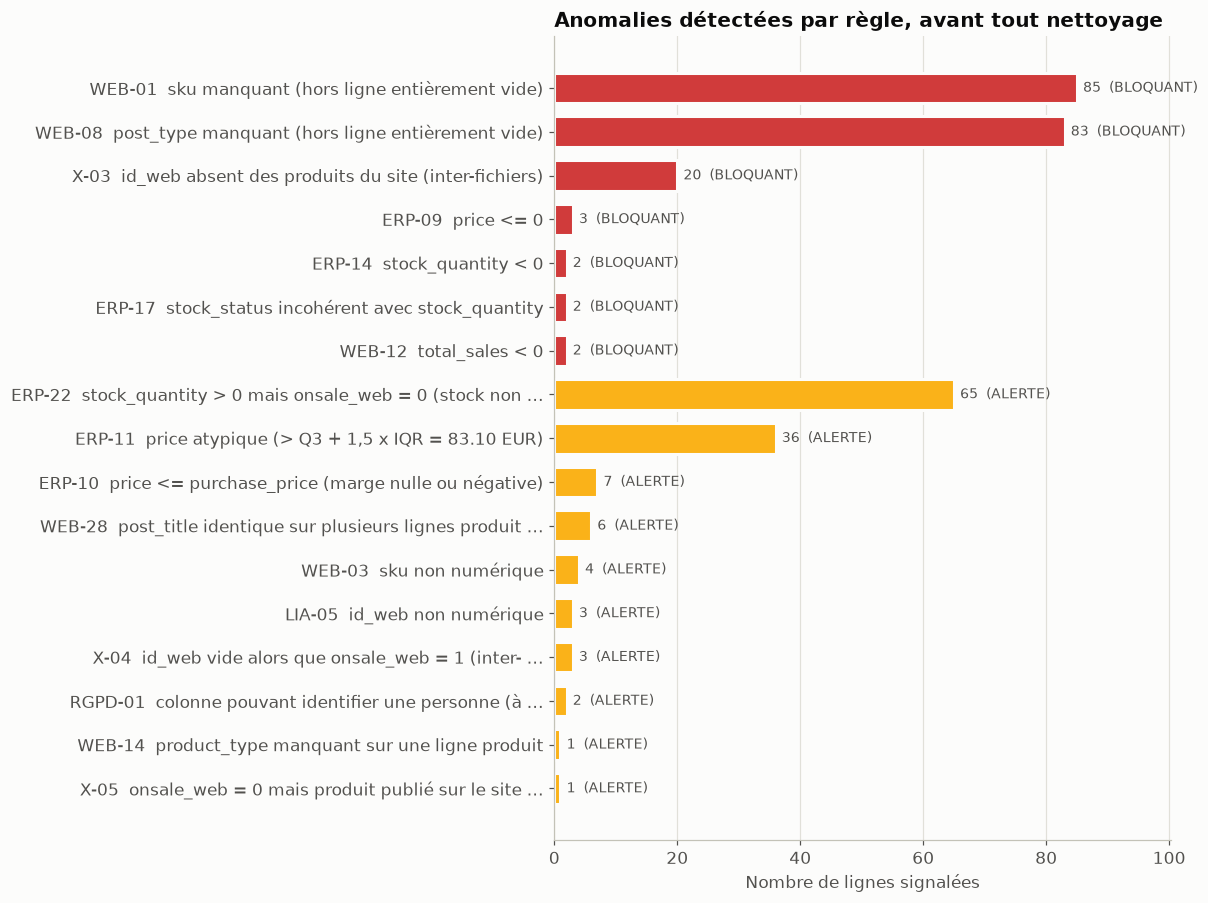

In [6]:
fig, ax = plt.subplots(figsize=(11, 0.42 * len(synthese) + 1.2))
ordre = synthese.iloc[::-1]                                  # la plus grande barre en haut
couleurs = ordre["niveau"].map({"BLOQUANT": CRITIQUE, "ALERTE": AVERTISSEMENT})
import textwrap
etiquettes = ordre["code"] + "  " + ordre["libelle"].map(lambda t: textwrap.shorten(t, width=52, placeholder=" …"))
ax.barh(etiquettes, ordre["nb_lignes"], color=couleurs, height=0.7, edgecolor=FOND, linewidth=2)
for y, (n, niv) in enumerate(zip(ordre["nb_lignes"], ordre["niveau"])):
    ax.text(n + 1, y, f"{n}  ({niv})", va="center", fontsize=9, color=ENCRE_2)
ax.set_axisbelow(True)
ax.set_xlabel("Nombre de lignes signalées")
ax.set_title("Anomalies détectées par règle, avant tout nettoyage")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, synthese["nb_lignes"].max() * 1.18)
plt.tight_layout()
plt.show()

### 2.3 — Rapport Excel pour les équipes

Le rapport est régénéré à chaque exécution : c'est ce qui rend le contrôle **rejouable à chaque export**. La colonne `ligne_excel` permet de retrouver la ligne dans le fichier d'origine (index + 2, l'en-tête occupant la ligne 1).

In [7]:
rapport = anomalies.assign(ligne_excel=anomalies["index_ligne"] + 2)[
    ["niveau", "code", "fichier", "libelle", "colonne", "index_ligne", "ligne_excel", "valeur"]]

with pd.ExcelWriter("rapport_qualite_donnees.xlsx") as fichier:
    synthese.to_excel(fichier, sheet_name="Synthèse", index=False)
    rapport.to_excel(fichier, sheet_name="Détail des anomalies", index=False)
print(f"rapport_qualite_donnees.xlsx : {len(synthese)} règles, {len(rapport)} lignes de détail")

rapport_qualite_donnees.xlsx : 17 règles, 325 lignes de détail


### 2.4 — Comparaison avec le récapitulatif du P6

Les nombres du P6 ci-dessous sont **repris tels qu'ils figuraient dans son tableau récapitulatif** (saisis à la main à l'époque). Ceux du P13 sont **calculés** par les règles. Tout écart est expliqué.

In [8]:
def nb(code_regle):
    """Nombre de lignes signalées par une règle (0 si la règle ne s'est pas déclenchée)."""
    return int((anomalies["code"] == code_regle).sum())

comparaison = pd.DataFrame([
    ("1",  "stock_status incohérent",             2,  "ERP-17", nb("ERP-17"), "Identique."),
    ("2",  "Prix de vente ≤ 0",                   3,  "ERP-09", nb("ERP-09"), "Identique."),
    ("3",  "Stock négatif",                       2,  "ERP-14", nb("ERP-14"), "Identique."),
    ("4",  "Vente à perte",                       4,  "ERP-10", nb("ERP-10"),
     "Le P13 inclut les 3 prix négatifs ; le code du P6 en trouvait aussi 7."),
    ("5",  "sku manquant",                        85, "WEB-01", nb("WEB-01"),
     "Identique, mais 2 de ces lignes sont de vrais produits, pas des images."),
    ("7",  "Ventes négatives",                    2,  "WEB-12", nb("WEB-12"),
     "Ce sont les 2 produits sans sku : la correction du P6 n'avait aucun effet."),
    ("8",  "sku non numérique",                   4,  "WEB-03", nb("WEB-03"),
     "Le P6 les disait exclus par la jointure : 2 produits sont en réalité joints."),
    ("9",  "id_web vide",                         91, "X-04",   nb("X-04"),
     "Vide normal pour un produit hors ligne ; seuls 3 produits EN VENTE sont anormaux."),
    ("10", "id_web absent du site (orphelin)",    20, "X-03",   nb("X-03"), "Identique."),
    ("11", "Prix atypique (méthode IQR)",         31, "ERP-11", nb("ERP-11"),
     "Seuil calculé sur les 825 produits ERP et non sur les 714 du jeu final."),
], columns=["n° P6", "anomalie", "nb annoncé P6", "règle P13", "nb calculé P13", "explication de l'écart"])
comparaison["écart"] = comparaison["nb calculé P13"] - comparaison["nb annoncé P6"]
comparaison

,n° P6,anomalie,nb annoncé P6,règle P13,nb calculé P13,explication de l'écart,écart
0,1,stock_status incohérent,2,ERP-17,2,Identique.,0
1,2,Prix de vente ≤ 0,3,ERP-09,3,Identique.,0
2,3,Stock négatif,2,ERP-14,2,Identique.,0
3,4,Vente à perte,4,ERP-10,7,Le P13 inclut les 3 prix négatifs ; le code du P6 en trouvait aussi 7.,3
4,5,sku manquant,85,WEB-01,85,"Identique, mais 2 de ces lignes sont de vrais produits, pas des images.",0
5,7,Ventes négatives,2,WEB-12,2,Ce sont les 2 produits sans sku : la correction du P6 n'avait aucun effet.,0
6,8,sku non numérique,4,WEB-03,4,Le P6 les disait exclus par la jointure : 2 produits sont en réalité joints.,0
7,9,id_web vide,91,X-04,3,Vide normal pour un produit hors ligne ; seuls 3 produits EN VENTE sont anor...,-88
8,10,id_web absent du site (orphelin),20,X-03,20,Identique.,0
9,11,Prix atypique (méthode IQR),31,ERP-11,36,Seuil calculé sur les 825 produits ERP et non sur les 714 du jeu final.,5


**Ce qu'il faut retenir.** Le contrôle déclenche 17 règles sur 64 et signale 325 lignes (197 bloquantes, 128 alertes). Les écarts avec le P6 ne viennent pas des données, mais de la façon de compter : le P6 retirait les prix négatifs des ventes à perte, et il classait les 91 `id_web` vides en erreur alors que seuls 3 produits **en vente** sont concernés.

Le contrôle apporte six constats que le P6 n'avait pas :
- **ERP-22** : 65 produits ont du stock mais ne sont pas en vente ;
- **X-04** : 3 produits en vente n'ont pas d'`id_web`, donc sont absents du site ;
- **X-05** : 1 produit hors vente reste publié ;
- **WEB-14** : le bon cadeau n'a pas de famille ;
- **RGPD-01** : 2 colonnes peuvent identifier une personne ;
- **WEB-28** : 3 paires de fiches produit portent le même libellé.

<div style="background-color: RGB(51,165,182); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Étape 3 — Nettoyage piloté par les règles</h2>
</div>

Les corrections sont les mêmes qu'au P6, mais chacune s'appuie sur les lignes **désignées par une règle** et laisse une trace dans un journal. Les données brutes restent intactes (copies de travail).

In [9]:
erp, web, liaison = erp_brut.copy(), web_brut.copy(), liaison_brut.copy()
journal = []


def lignes(code_regle):
    """Index des lignes signalées par une règle."""
    idx = anomalies.loc[anomalies["code"] == code_regle, "index_ligne"].dropna()
    return idx.astype(int).unique()


# ERP-14 : stock négatif → 0 (un stock physique ne peut pas être négatif)
idx = lignes("ERP-14")
erp.loc[idx, "stock_quantity"] = 0
journal.append(("ERP-14", "stock négatif remis à 0", len(idx)))

# ERP-17 : stock_status recalculé depuis stock_quantity (règle de gestion), après la correction ci-dessus
avant = erp["stock_status"].copy()
erp["stock_status"] = np.where(erp["stock_quantity"] > 0, "instock", "outofstock")
journal.append(("ERP-17", "stock_status recalculé depuis stock_quantity", int((avant != erp["stock_status"]).sum())))

# ERP-09 : prix ≤ 0 → valeur inconnue (on ne l'invente pas)
idx = lignes("ERP-09")
erp.loc[idx, "price"] = np.nan
journal.append(("ERP-09", "prix ≤ 0 passé en valeur inconnue", len(idx)))

# WEB-12 : ventes négatives → 0
idx = lignes("WEB-12")
web.loc[idx, "total_sales"] = 0
journal.append(("WEB-12", "ventes négatives remises à 0", len(idx)))

# WEB-14 : produit sans famille → famille explicite (seul cas : le bon cadeau, vrai article de l'ERP)
idx = lignes("WEB-14")
assert web.loc[idx, "sku"].eq("bon-cadeau-25-euros").all(), "Un autre produit sans famille est apparu"
web.loc[idx, "product_type"] = "Bon cadeau"
journal.append(("WEB-14", "famille « Bon cadeau » renseignée", len(idx)))

pd.DataFrame(journal, columns=["règle", "correction", "lignes modifiées"])

,règle,correction,lignes modifiées
0,ERP-14,stock négatif remis à 0,2
1,ERP-17,stock_status recalculé depuis stock_quantity,2
2,ERP-09,prix ≤ 0 passé en valeur inconnue,3
3,WEB-12,ventes négatives remises à 0,2
4,WEB-14,famille « Bon cadeau » renseignée,1


**Note sur `13127-1` et les fiches en double (règle WEB-28).** Le P6 recommandait de « corriger `13127-1` en `13127` ». Ce serait une erreur : `13127` est le millésime 2012, `13127-1` le 2007. En revanche, `13127-1` porte exactement le même libellé que la fiche `16034` (même vin, même millésime, même prix de vente), et WordPress a suffixé son adresse par « -2 », ce qu'il fait quand une fiche du même nom existe déjà. C'est donc très probablement un **doublon de fiche**. Deux autres paires sont dans le même cas. Aucune correction n'est faite ici : la fusion des fiches est une décision métier, remontée en alerte.

In [10]:
doublons = anomalies.loc[anomalies["code"].eq("WEB-28"), "index_ligne"].astype(int)
(web_brut.loc[doublons, ["sku", "post_title", "post_name", "post_date"]]
   .merge(liaison_brut.assign(sku=liaison_brut["id_web"].map(cq._cle)), left_on=web_brut.loc[doublons, "sku"].map(cq._cle),
          right_on="sku", how="left", suffixes=("", "_liaison"))
   .merge(erp_brut[["product_id", "price", "purchase_price", "stock_quantity"]], on="product_id", how="left")
   .drop(columns=["key_0", "sku_liaison", "id_web"], errors="ignore")
   .sort_values(["post_title", "post_date"]))

,sku,post_title,post_name,post_date,product_id,price,purchase_price,stock_quantity
4,16034,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,clos-du-mont-olivet-chateauneuf-du-pape-2007,2018-09-25 15:35:26,5465,54.8,28.60,12
0,13127-1,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,clos-du-mont-olivet-chateauneuf-du-pape-2007-2,2020-06-09 15:42:04,7247,54.8,27.18,6
3,15292,Domaine Hauvette IGP Alpilles Jaspe 2017,domaine-hauvette-igp-alpilles-jaspe-2017-2,2018-02-28 13:43:33,4288,26.7,14.48,26
5,16068,Domaine Hauvette IGP Alpilles Jaspe 2017,domaine-hauvette-igp-alpilles-jaspe-2017,2020-02-22 14:28:32,6665,27.7,14.60,16
2,14000,Marc Colin Et Fils Chassagne-Montrachet Blanc Les Vide-Bourses 1er Cru 2016,marc-colin-et-fils-chassagne-montrachet-blanc-vide-bourses-2016,2018-04-13 13:32:03,4597,61.6,33.42,7
1,14828,Marc Colin Et Fils Chassagne-Montrachet Blanc Les Vide-Bourses 1er Cru 2016,marc-colin-et-fils-chassagne-montrachet-blanc-les-vide-bourses-1er-cru-2016,2018-11-26 09:52:56,5544,61.6,31.51,0


<div style="background-color: RGB(51,165,182); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Étape 4 — Jointure vérifiée des trois fichiers</h2>
</div>

Le P6 vérifiait sa jointure en comparant `product_id` à `sku` (cellule 59) : deux clés qui n'ont rien à voir, d'où un résultat sans signification. Ici, les clés sont normalisées avec la **même fonction que les règles qualité** (`15298`, `15298.0` et `"15298"` donnent la même clé), et chaque étape est vérifiée par une assertion : si un futur export casse la jointure, le notebook s'arrête au lieu de produire de faux chiffres.

In [11]:
web_produits = web[web["post_type"].eq("product") & web["sku"].notna()].copy()
web_produits["cle"] = web_produits["sku"].map(cq._cle)
liaison["cle"] = liaison["id_web"].map(cq._cle)
assert web_produits["cle"].is_unique, "Deux lignes produit partagent le même sku"
assert liaison["cle"].dropna().is_unique, "Deux produits ERP pointent vers le même id_web"

# Étape A : ERP + liaison (relation 1-1 sur product_id)
etape_a = erp.merge(liaison, on="product_id", how="outer", validate="one_to_one", indicator=True)
assert etape_a["_merge"].eq("both").all(), "Des product_id ne se retrouvent pas entre ERP et liaison"

# Étape B : + site web (plusieurs produits ERP sans id_web → clé vide, donc many_to_one)
etape_b = etape_a.drop(columns="_merge").merge(web_produits, on="cle", how="left",
                                               validate="many_to_one", indicator=True)
etape_b["statut_jointure"] = np.select(
    [etape_b["_merge"].eq("both"), etape_b["cle"].isna()],
    ["joint au site", "sans id_web (pas encore en ligne)"],
    default="id_web absent du site (orphelin)")
etape_b["statut_jointure"].value_counts()

statut_jointure
joint au site                        714
sans id_web (pas encore en ligne)     91
id_web absent du site (orphelin)      20
Name: count, dtype: int64

In [12]:
df = (etape_b[etape_b["_merge"].eq("both")]
      .drop(columns=["_merge", "statut_jointure"])
      .rename(columns={"post_title": "produit", "product_type": "type_produit", "total_sales": "qte_vendue"})
      .reset_index(drop=True))
assert len(df) == 714, f"{len(df)} références jointes au lieu de 714"
print(f"Jeu d'analyse : {len(df)} références × {df.shape[1]} colonnes")
print("Codes non numériques présents dans le jeu final :",
      df.loc[~df["sku"].map(cq._cle_numerique), ["sku", "produit"]].to_dict("records"))

Jeu d'analyse : 714 références × 37 colonnes
Codes non numériques présents dans le jeu final : [{'sku': 'bon-cadeau-25-euros', 'produit': 'Bon cadeau de 25€'}, {'sku': '13127-1', 'produit': 'Clos du Mont-Olivet Châteauneuf-du-Pape 2007'}]


<div style="background-color: RGB(51,165,182); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Étape 5 — Chiffre d'affaires et loi de Pareto</h2>
</div>

In [13]:
df["ca"] = df["price"] * df["qte_vendue"]
ca_total = df["ca"].sum()
ca_famille = df.groupby("type_produit")["ca"].sum().sort_values(ascending=False)

# Contrôle de cohérence : la somme par famille doit retomber sur le total (ce n'était pas le cas au P6,
# le bon cadeau sans famille disparaissait du regroupement)
assert np.isclose(ca_famille.sum(), ca_total)

print(f"CA total du site : {ca_total:,.2f} €".replace(",", " "))
(ca_famille.to_frame("CA (€)").assign(**{"part (%)": lambda t: (100 * t["CA (€)"] / ca_total).round(1)}))

CA total du site : 143 680.10 €


,CA (€),part (%)
type_produit,,
Vin,123518.0,86.0
Champagne,12928.6,9.0
Cognac,3170.2,2.2
Whisky,2886.6,2.0
Gin,504.0,0.4
Huile d'olive,497.7,0.3
Bon cadeau,175.0,0.1


**Ordre reproductible.** L'algorithme de tri par défaut de pandas (`quicksort`) n'est pas stable : l'ordre des ex æquo peut changer d'une version à l'autre, et c'est ce qui modifiait le palmarès du P6. Le paramètre `kind="stable"` ne s'applique qu'aux tris sur une seule colonne (documentation pandas). On départage donc explicitement les ex æquo par le nom du produit, puis par `product_id`, unique : l'ordre est alors entièrement déterminé.

In [14]:
palmares = df.sort_values(["ca", "produit", "product_id"], ascending=[False, True, True]).reset_index(drop=True)
palmares["cumul_ca_pct"] = 100 * palmares["ca"].cumsum() / ca_total
palmares["rang_pct"] = 100 * (np.arange(len(palmares)) + 1) / len(palmares)

nb_80 = int((palmares["cumul_ca_pct"] < 80).sum() + 1)          # articles nécessaires pour ATTEINDRE 80 %
palmares["classe_abc"] = np.select([palmares.index < nb_80, palmares["cumul_ca_pct"].shift(fill_value=0) < 95],
                                   ["A", "B"], default="C")
print(f"{nb_80} articles ({100 * nb_80 / len(palmares):.1f} % du catalogue) font 80 % du CA")
palmares["classe_abc"].value_counts().sort_index()

435 articles (60.9 % du catalogue) font 80 % du CA


classe_abc
A    435
B    171
C    108
Name: count, dtype: int64

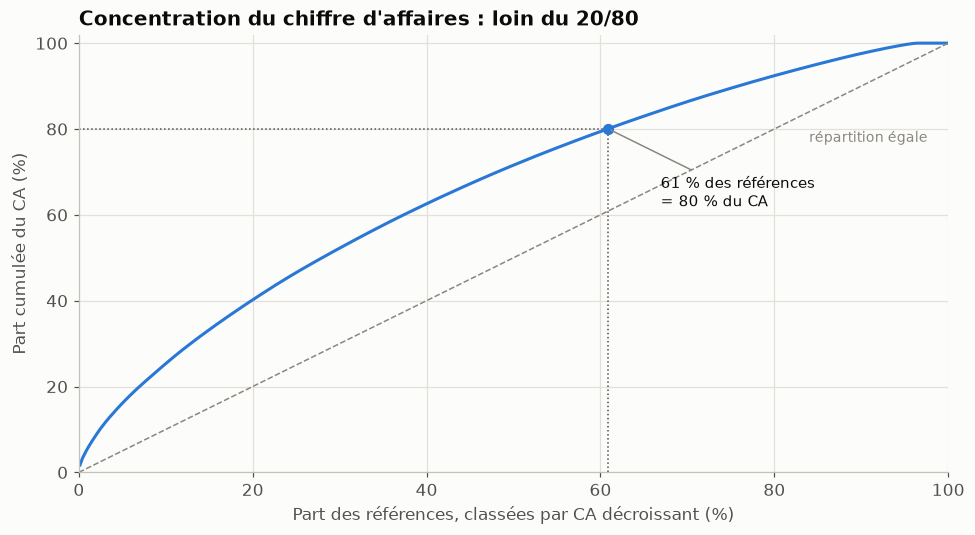

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(palmares["rang_pct"], palmares["cumul_ca_pct"], color=BLEU, linewidth=2)
ax.plot([0, 100], [0, 100], color=MUET, linewidth=1, linestyle="--")
x80 = 100 * nb_80 / len(palmares)
ax.plot([x80, x80, 0], [0, 80, 80], color=ENCRE_2, linewidth=1, linestyle=":")
ax.scatter([x80], [80], s=40, color=BLEU, zorder=3)
ax.annotate(f"{x80:.0f} % des références\n= 80 % du CA", (x80, 80), xytext=(x80 + 6, 62),
            color=ENCRE, fontsize=10, arrowprops=dict(arrowstyle="-", color=MUET))
ax.text(84, 77, "répartition égale", color=MUET, fontsize=9)
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_xlabel("Part des références, classées par CA décroissant (%)")
ax.set_ylabel("Part cumulée du CA (%)")
ax.set_title("Concentration du chiffre d'affaires : loin du 20/80")
plt.tight_layout()
plt.show()

**Ce qu'il faut retenir.** Le CA reste de 143 680,10 €, comme au P6. La somme par famille retombe désormais sur ce total : au P6, les 175 € du bon cadeau (sans famille) disparaissaient du regroupement.

- Il faut **435 références, soit 60,9 % du catalogue, pour faire 80 % du CA**. Le P6 en comptait 434, car il n'incluait pas l'article qui fait franchir le seuil.
- Le CA est donc peu concentré. BottleNeck vend un catalogue large plutôt que quelques produits phares, ce qui rend le pilotage du stock référence par référence d'autant plus important.
- La classification ABC qui en découle compte 435 références en A, 171 en B et 108 en C.

<div style="background-color: RGB(51,165,182); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Étape 6 — Stocks : couverture et stock dormant (enrichi)</h2>
</div>

### 6.1 — Une hypothèse à rendre explicite

Le P6 calculait les mois de stock par `stock / (ventes / 12)`, ce qui suppose que `total_sales` couvre **12 mois**. Or `total_sales` est un **cumul depuis la mise en ligne**, et les produits ont été créés entre 2018 et 2020. On garde l'hypothèse des 12 mois pour rester comparable au P6, et on mesure sa sensibilité avec une seconde hypothèse fondée sur l'ancienneté réelle de chaque produit.

In [16]:
date_reference = web_brut["post_modified"].max()      # dernière modification = meilleure approximation de la date d'export
print(f"Création des produits : du {df['post_date'].min():%d/%m/%Y} au {df['post_date'].max():%d/%m/%Y}")
print(f"Date de référence (dernière modification du site) : {date_reference:%d/%m/%Y}")

df["valo_stock"] = df["stock_quantity"] * df["purchase_price"]
anciennete_mois = ((date_reference - df["post_date"]).dt.days / 30.44).clip(lower=1)
df["couv_h1_mois"] = df["stock_quantity"] / (df["qte_vendue"] / 12)                 # hypothèse P6 : 12 mois
df["couv_h2_mois"] = df["stock_quantity"] / (df["qte_vendue"] / anciennete_mois)    # ventes / ancienneté réelle
df.loc[df["qte_vendue"].eq(0), ["couv_h1_mois", "couv_h2_mois"]] = np.nan          # pas de vente : couverture infinie

sensibilite = pd.DataFrame({
    "hypothèse": ["H1 — ventes sur 12 mois (P6)", "H2 — ventes sur l'ancienneté réelle"],
    "réf. > 24 mois de stock": [int((df["couv_h1_mois"] > 24).sum()), int((df["couv_h2_mois"] > 24).sum())],
    "valeur (€)": [df.loc[df["couv_h1_mois"] > 24, "valo_stock"].sum().round(0),
                   df.loc[df["couv_h2_mois"] > 24, "valo_stock"].sum().round(0)]})
sensibilite

Création des produits : du 08/02/2018 au 20/07/2020
Date de référence (dernière modification du site) : 27/08/2020


,hypothèse,réf. > 24 mois de stock,valeur (€)
0,H1 — ventes sur 12 mois (P6),450,220378.0
1,H2 — ventes sur l'ancienneté réelle,600,249645.0


### 6.2 — Le stock dormant, au complet

Trois formes de stock immobilisé, dont **deux étaient invisibles au P6** : le stock des produits hors vente (règle ERP-22, sur tout l'ERP et pas seulement les 714 produits du site) et le stock des produits en vente qui n'ont jamais vendu.

In [17]:
hors_vente = erp[erp["onsale_web"].eq(0) & erp["stock_quantity"].gt(0)]
sans_vente = df[df["qte_vendue"].eq(0) & df["stock_quantity"].gt(0)]
sur_stock = df[df["couv_h1_mois"] > 24]

dormant = pd.DataFrame([
    ("Hors vente avec stock (ERP-22)", len(hors_vente), hors_vente["stock_quantity"].sum(),
     (hors_vente["stock_quantity"] * hors_vente["purchase_price"]).sum(), "non (nouveau)"),
    ("En vente, aucune vente", len(sans_vente), sans_vente["stock_quantity"].sum(),
     sans_vente["valo_stock"].sum(), "non (nouveau)"),
    ("Plus de 24 mois de stock (H1)", len(sur_stock), sur_stock["stock_quantity"].sum(),
     sur_stock["valo_stock"].sum(), "en partie (flop 20 seulement)"),
], columns=["forme de stock dormant", "références", "bouteilles", "valeur au prix d'achat (€)", "vu au P6"])
dormant["valeur au prix d'achat (€)"] = dormant["valeur au prix d'achat (€)"].round(0)
dormant

,forme de stock dormant,références,bouteilles,valeur au prix d'achat (€),vu au P6
0,Hors vente avec stock (ERP-22),65,1115,21403.0,non (nouveau)
1,"En vente, aucune vente",3,255,14959.0,non (nouveau)
2,Plus de 24 mois de stock (H1),450,14607,220378.0,en partie (flop 20 seulement)


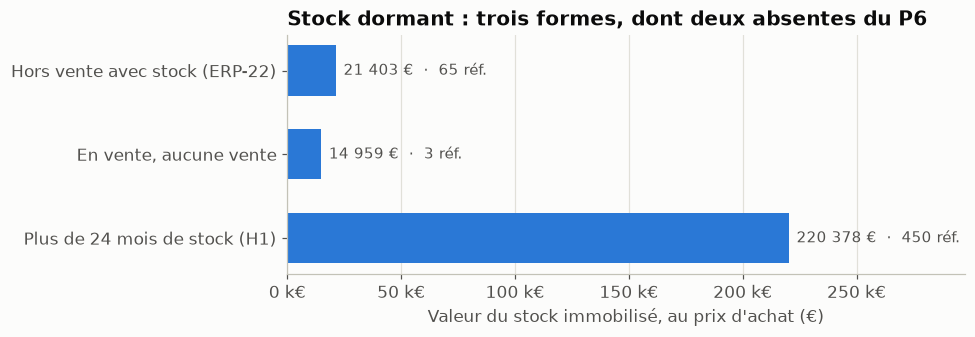

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ordre = dormant.iloc[::-1]
ax.barh(ordre["forme de stock dormant"], ordre["valeur au prix d'achat (€)"], color=BLEU, height=0.6)
ax.set_axisbelow(True)
marge_txt = dormant["valeur au prix d'achat (€)"].max() * 0.015
for y, (v, r) in enumerate(zip(ordre["valeur au prix d'achat (€)"], ordre["références"])):
    ax.text(v + marge_txt, y, f"{v:,.0f} €  ·  {r} réf.".replace(",", " "), va="center", fontsize=10, color=ENCRE_2)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: f"{x / 1000:.0f} k€"))
ax.set_xlim(0, dormant["valeur au prix d'achat (€)"].max() * 1.35)
ax.set_xlabel("Valeur du stock immobilisé, au prix d'achat (€)")
ax.set_title("Stock dormant : trois formes, dont deux absentes du P6")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 6.3 — Matrice ABC × couverture

Croiser l'importance commerciale (classe ABC sur le CA) et la couverture de stock dit **où agir** : un produit A en rupture coûte des ventes, un produit C avec deux ans de stock immobilise de la trésorerie.

In [19]:
df = df.merge(palmares[["product_id", "classe_abc"]], on="product_id", how="left")
classes = ["Rupture", "< 3 mois", "3–12 mois", "12–24 mois", "> 24 mois", "Stock sans vente"]
df["classe_couverture"] = pd.Categorical(np.select(
    [df["stock_quantity"].eq(0), df["qte_vendue"].eq(0), df["couv_h1_mois"] < 3,
     df["couv_h1_mois"] < 12, df["couv_h1_mois"] <= 24],
    ["Rupture", "Stock sans vente", "< 3 mois", "3–12 mois", "12–24 mois"], default="> 24 mois"),
    categories=classes, ordered=True)

matrice_nb = pd.crosstab(df["classe_abc"], df["classe_couverture"], dropna=False)
matrice_valo = df.pivot_table(index="classe_abc", columns="classe_couverture", values="valo_stock",
                              aggfunc="sum", observed=False).fillna(0)
matrice_nb

classe_couverture,Rupture,< 3 mois,3–12 mois,12–24 mois,> 24 mois,Stock sans vente
classe_abc,,,,,,
A,15,0,1,168,251,0
B,4,0,0,35,132,0
C,26,0,0,12,67,3


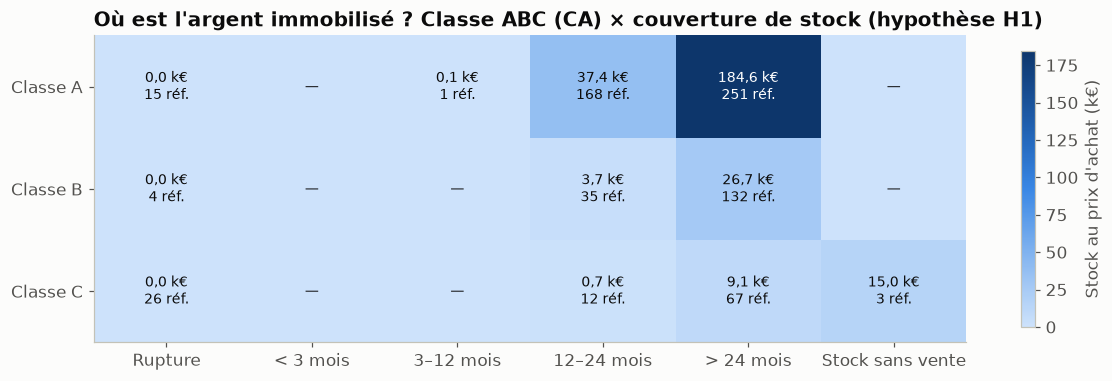

In [20]:
from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(11, 3.6))
carte = LinearSegmentedColormap.from_list("bleus", BLEUS)
valeurs_k = matrice_valo.values / 1000
image = ax.imshow(valeurs_k, cmap=carte, aspect="auto", vmin=0)
ax.set_xticks(range(len(classes)), classes)
ax.set_yticks(range(3), [f"Classe {c}" for c in matrice_valo.index])
ax.grid(False)
for i in range(valeurs_k.shape[0]):
    for j in range(valeurs_k.shape[1]):
        n_ref = matrice_nb.values[i, j]
        clair = valeurs_k[i, j] > 0.55 * valeurs_k.max()
        valeur_txt = f"{valeurs_k[i, j]:.1f}".replace(".", ",")
        texte = "—" if n_ref == 0 else f"{valeur_txt} k€\n{n_ref} réf."
        ax.text(j, i, texte, ha="center", va="center", fontsize=9, color="white" if clair else ENCRE)
fig.colorbar(image, ax=ax, label="Stock au prix d'achat (k€)", shrink=0.9)
ax.set_title("Où est l'argent immobilisé ? Classe ABC (CA) × couverture de stock (hypothèse H1)")
plt.tight_layout()
plt.show()

**Ce qu'il faut retenir.**

- **Le stock est surdimensionné, quelle que soit l'hypothèse.** Le stock compte 16 740 bouteilles pour 5 751 ventes cumulées, soit 2,9 fois plus.
  - Avec l'hypothèse du P6 (ventes sur 12 mois), la couverture médiane des produits vendus atteint 28,8 mois, et **450 références dépassent 24 mois, soit 79,5 % de la valeur du stock (220 378 €)**.
  - Avec l'ancienneté réelle des produits, c'est pire : 58,9 mois de couverture médiane et 600 références au-delà de 24 mois.
- **Même les produits qui font le chiffre d'affaires sont trop stockés.** En classe A, 251 références sur 435 dépassent 24 mois, pour 184,6 k€.
- **À l'inverse, 45 références sont en rupture**, dont 15 de classe A, qui pesaient 5 790 € de CA cumulé. Le problème est donc de répartir le stock, pas seulement d'en avoir trop.
- **Deux formes de stock dormant étaient invisibles au P6 :**
  - 65 produits hors vente avec du stock, soit 1 115 bouteilles et 21 403 €. 64 d'entre eux n'ont pas de correspondance sur le site, et n'apparaissaient donc pas dans le jeu final du P6.
  - 3 produits en vente qui n'ont jamais vendu, pour 14 959 €. Deux champagnes en font l'essentiel, dont l'Egly-Ouriet dont le prix est manifestement erroné (voir l'étape 7).

**Limite.** Ces couvertures dépendent de la période réelle de `total_sales`, que les fichiers ne précisent pas. Il faut la valider avec BottleNeck avant toute décision de déstockage.

<div style="background-color: RGB(51,165,182); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Étape 7 — Marges</h2>
</div>

In [21]:
df["taux_marge"] = 100 * (df["price"] - df["purchase_price"]) / df["price"]
perte = df[df["taux_marge"] < 0]
print(f"Taux de marge moyen : {df['taux_marge'].mean():.1f} % "
      f"(hors produits à perte : {df.loc[df['taux_marge'] >= 0, 'taux_marge'].mean():.1f} %)")
perte[["product_id", "produit", "price", "purchase_price", "taux_marge", "stock_quantity", "qte_vendue"]]

Taux de marge moyen : 47.4 % (hors produits à perte : 48.2 %)


,product_id,produit,price,purchase_price,taux_marge,stock_quantity,qte_vendue
201,4355,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,12.65,77.48,-512.490119,97,0.0


In [22]:
(df[df["taux_marge"] >= 0].groupby("type_produit")["taux_marge"]
   .agg(["mean", "count"]).rename(columns={"mean": "taux de marge moyen (%)", "count": "références"})
   .round(1).sort_values("taux de marge moyen (%)", ascending=False))

,taux de marge moyen (%),références
type_produit,,
Cognac,54.2,8
Whisky,54.1,14
Gin,52.3,2
Vin,48.3,658
Bon cadeau,46.8,1
Champagne,40.4,27
Huile d'olive,37.5,3


**Ce qu'il faut retenir.**

- Le taux de marge moyen est de 47,4 % (48,2 % hors vente à perte), comme au P6.
- **La seule vente à perte du jeu final est très probablement une erreur de prix.** Le Champagne Egly-Ouriet Grand Cru Blanc de Noirs est affiché à 12,65 € pour un prix d'achat de 77,48 €, et il a 97 bouteilles en stock sans aucune vente. Le corriger est prioritaire : il immobilise aussi 7 516 € de stock dormant.
- Le bon cadeau, désormais rattaché à une famille, dégage 46,8 % de marge.

<div style="background-color: RGB(51,165,182); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Étape 8 — Corrélations : Pearson et Spearman</h2>
</div>

Le P6 utilisait Pearson, qui mesure une relation **linéaire** et se laisse tirer par les valeurs extrêmes (prix jusqu'à 225 €). Spearman travaille sur les **rangs** : il convient mieux à des distributions asymétriques. On retire aussi le CA de la matrice : c'est prix × quantité, sa corrélation avec ces deux variables est mécanique.

In [23]:
variables = ["price", "purchase_price", "stock_quantity", "qte_vendue", "taux_marge"]
base = df[variables].dropna()
pearson, spearman = base.corr(method="pearson"), base.corr(method="spearman")

paires = [("price", "purchase_price"), ("price", "qte_vendue"), ("stock_quantity", "qte_vendue"),
          ("taux_marge", "price"), ("stock_quantity", "price")]
pd.DataFrame([(f"{a} / {b}", round(pearson.loc[a, b], 2), round(spearman.loc[a, b], 2)) for a, b in paires],
             columns=["paire", "Pearson", "Spearman"])

,paire,Pearson,Spearman
0,price / purchase_price,0.98,0.99
1,price / qte_vendue,-0.52,-0.70
2,stock_quantity / qte_vendue,0.44,0.76
3,taux_marge / price,0.02,-0.05
4,stock_quantity / price,-0.11,-0.57


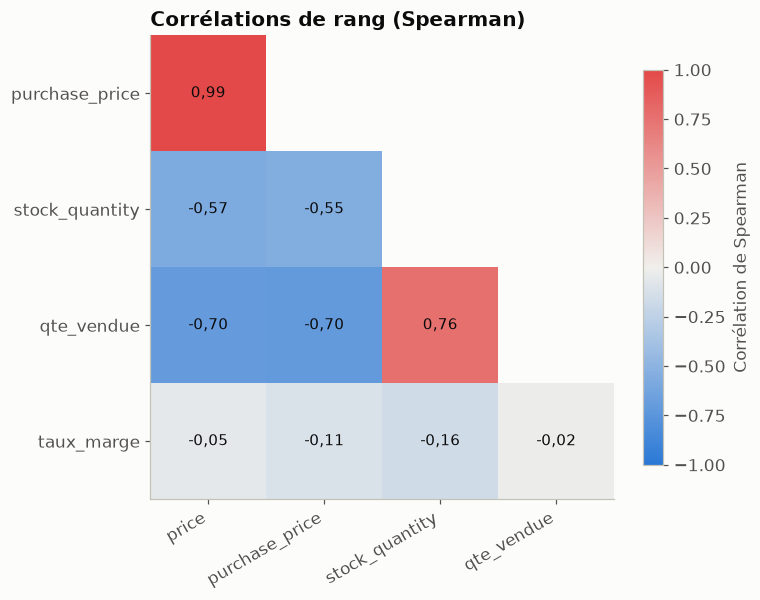

In [24]:
fig, ax = plt.subplots(figsize=(7, 5.6))
carte_div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
bloc = spearman.values[1:, :-1]                       # triangle inférieur, sans la diagonale (toujours 1)
masque = np.triu(np.ones_like(bloc, dtype=bool), k=1)
image = ax.imshow(np.ma.array(bloc, mask=masque), cmap=carte_div, vmin=-1, vmax=1)
ax.set_xticks(range(len(variables) - 1), variables[:-1], rotation=30, ha="right")
ax.set_yticks(range(len(variables) - 1), variables[1:])
ax.grid(False)
for i in range(bloc.shape[0]):
    for j in range(i + 1):
        ax.text(j, i, f"{bloc[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=10, color=ENCRE)
fig.colorbar(image, ax=ax, label="Corrélation de Spearman", shrink=0.85)
ax.set_title("Corrélations de rang (Spearman)")
plt.tight_layout()
plt.show()

**Ce qu'il faut retenir.**

- **Prix de vente et prix d'achat : 0,98 en Pearson, 0,99 en Spearman.** Le constat du P6 est confirmé : le prix de vente suit le prix d'achat.
- **Prix et ventes : −0,52 en Pearson, −0,70 en Spearman.** Les produits moins chers se vendent mieux, et la relation est plus forte que ce qu'en disait le P6.
- **Stock et ventes : la conclusion du P6 est corrigée.** Le P6 concluait : « Corrélation faible. Le stock n'est pas lié aux ventes passées. » (Pearson 0,44). Spearman donne 0,76 : les produits les plus vendus sont aussi les plus stockés. L'approvisionnement suit donc bien les ventes, mais à un niveau trop élevé (étape 6).
- **Stock et prix : −0,57 en Spearman** (−0,11 en Pearson). On stocke moins les produits chers, ce que Pearson masquait.

<div style="background-color: RGB(51,165,182); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Étape 9 — Export et contrôles de non-régression</h2>
</div>

In [25]:
colonnes_export = ["product_id", "sku", "produit", "type_produit", "onsale_web", "price", "purchase_price",
                   "taux_marge", "stock_quantity", "stock_status", "qte_vendue", "ca", "classe_abc",
                   "valo_stock", "couv_h1_mois", "couv_h2_mois", "classe_couverture"]
df[colonnes_export].to_excel("bottleneck_dataset_clean_P13.xlsx", index=False)
print(f"bottleneck_dataset_clean_P13.xlsx : {len(df)} lignes × {len(colonnes_export)} colonnes")

bottleneck_dataset_clean_P13.xlsx : 714 lignes × 17 colonnes


Ces assertions comparent les indicateurs clés aux valeurs de la présentation CODIR du P6. Elles ne servent pas à saisir des résultats en dur : elles **alertent** si une modification du code ou des données change un chiffre déjà communiqué à la direction.

In [26]:
REFERENCE_P6 = {"références": 714, "CA total (€)": 143_680.10, "unités vendues": 5_751,
                "unités en stock": 16_740, "valorisation du stock (€)": 277_328.07}
obtenu = {"références": len(df), "CA total (€)": round(ca_total, 2), "unités vendues": int(df["qte_vendue"].sum()),
          "unités en stock": int(df["stock_quantity"].sum()),
          "valorisation du stock (€)": round(df["valo_stock"].sum(), 2)}
for cle, attendu in REFERENCE_P6.items():
    assert np.isclose(obtenu[cle], attendu), f"{cle} : {obtenu[cle]} au lieu de {attendu}"
    print(f"OK  {cle:<26} {obtenu[cle]:>12,}".replace(",", " "))

OK  références                          714
OK  CA total (€)                  143 680.1
OK  unités vendues                    5 751
OK  unités en stock                  16 740
OK  valorisation du stock (€)    277 328.07


<div style="background-color: RGB(255,114,0); padding: 14px;">
<h2 style="margin: 0; color: #fff;">Synthèse et recommandations</h2>
</div>

### Recommandations, par priorité

**Priorité 1 — Avant la migration vers le nouvel ERP**
1. Brancher `controles_qualite.py` en contrôle d'entrée : aucun export ne doit être chargé tant qu'il reste une ligne BLOQUANT. Le rapport Excel est la liste de travail des équipes.
2. Corriger les anomalies bloquantes :
    - les 83 lignes du site sans sku ni type de contenu ;
    - les 2 produits Pierre Jean Villa sans sku ;
    - les 20 `id_web` orphelins ;
    - les 2 stocks négatifs ;
    - les 3 prix négatifs.
3. Vérifier et corriger le prix du Champagne Egly-Ouriet Blanc de Noirs (12,65 €).

**Priorité 2 — Trésorerie : libérer le stock immobilisé**
1. Décider du sort des 65 produits hors vente qui ont du stock (21 403 €) : remise en vente, promotion ou retour fournisseur.
2. Traiter les 3 produits en vente sans aucune vente (14 959 €).
3. Revoir les règles de réapprovisionnement à partir de la matrice ABC × couverture : 184,6 k€ de surstock en classe A, alors que 15 références A sont en rupture.

**Priorité 3 — Gouvernance des données**
1. Faire préciser par BottleNeck la période couverte par `total_sales` : toutes les couvertures en dépendent.
2. Pseudonymiser `post_author` et `guid` avant tout partage hors de l'entreprise.
3. Faire trancher les 3 paires de fiches en double (WEB-28), dont `13127-1` et `16034`. Ne pas renommer `13127-1` en `13127`, qui est un autre millésime, comme le proposait le P6.
4. Créer la famille « Bon cadeau » dans WooCommerce.

### Limites
- **Pas d'historique mensuel des ventes.** Les couvertures reposent sur une hypothèse de période (H1 ou H2), et l'on ne peut mesurer ni la saisonnalité, ni la variabilité de la demande (classification XYZ), ni calculer un stock de sécurité.
- **Les règles ont été produites par une IA**, sélectionnée et vérifiée sur un banc de test. Leurs seuils et leurs listes de valeurs restent à faire valider par le métier.
- **Le seuil « prix atypique » n'est qu'une alerte statistique** : un prix élevé n'est pas une erreur pour un caviste premium.

### Prochaines étapes
- Écrire les tests automatisés (`pytest`) du module de contrôle.
- Obtenir un historique de ventes mensuel, pour passer à la classification XYZ et au calcul de stocks de sécurité.
- Planifier l'exécution automatique du contrôle à chaque export.